# Notatnik 08 — LPPLS vs. modele ML (walk-forward)
Porównanie XGBoost, LightGBM, CatBoost, regresji logistycznej i drzewa decyzyjnego.
Dla każdego algorytmu trzy zestawy cech: Price-only, LPPLS-only, Price+LPPLS.
Cechy są obliczane wyłącznie z danych z dnia t lub wcześniejszych.
Przed każdą granicą kalibracyjną i testową usuwamy etykiety z przyszłości.
Domyślnie tylko spadek >=10% / 60 dni; RUN_ALL_NINE=True uruchamia 9 konfiguracji.

In [3]:
# W Jupyter, jeżeli brakuje pakietów, uruchom osobno:
# %pip install pandas numpy matplotlib scikit-learn xgboost lightgbm catboost
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             average_precision_score, f1_score)

ROOT = Path('.')
OUT = ROOT / '08_wyniki_modele'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
TEST_YEARS = [2021, 2022, 2023, 2024]
RUN_ALL_NINE = True
TARGET_CONFIGS = ([(d, h) for h in (30, 45, 60) for d in (10, 15, 20)]
                  if RUN_ALL_NINE else [(10, 60)])
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
MODEL_NAMES = ['LogisticRegression', 'DecisionTree', 'XGBoost', 'LightGBM', 'CatBoost']
print('Konfiguracje:', TARGET_CONFIGS)

Konfiguracje: [(10, 30), (15, 30), (20, 30), (10, 45), (15, 45), (20, 45), (10, 60), (15, 60), (20, 60)]


## 1. Wczytaj zbiór z notatnika 07 i pełne dopasowania LPPLS
Wymagane pliki:
- `wyniki_future_drop_07/lppls_future_drop_dataset.csv` (lub w bieżącym folderze),
- `lppls_rolling_results.csv` (wszystkie okna, nie tylko zaakceptowane).
Jeśli brakuje pierwszego pliku, wykonaj najpierw notatnik 07 na rzeczywistych cenach BTC.

In [4]:
def find_file(candidates):
    for path in map(Path, candidates):
        if path.exists():
            return path
    raise FileNotFoundError('Nie znaleziono pliku. Sprawdź ścieżki: ' + ', '.join(map(str, candidates)))

file07 = find_file([
    ROOT / '07_wyniki_future_drop' / 'lppls_future_drop_dataset.csv',
    ROOT / 'lppls_future_drop_dataset.csv'
])
filefits = find_file([
    ROOT / 'lppls_rolling_results.csv',
    ROOT / 'lppls_rolling_results_z_etykietami_baniek.csv'
])

base = pd.read_csv(file07)
base['date'] = pd.to_datetime(base['date'], utc=True).dt.tz_convert(None).dt.normalize()
base = base.sort_values('date').reset_index(drop=True)
for col in ['price', 'confidence', 'n_accepted', 'n_all']:
    base[col] = pd.to_numeric(base[col], errors='raise')
assert base.date.is_unique and base.date.is_monotonic_increasing
assert base.price.notna().all() and base.price.gt(0).all()
assert base.confidence.between(0, 1).all()
assert base.date.diff().dropna().eq(pd.Timedelta(days=1)).all(), 'Brakuje dni w zbiorze 07'

for drop, horizon in TARGET_CONFIGS:
    y_col, e_col = f'drop_{drop}_h{horizon}', f'label_end_h{horizon}'
    assert y_col in base.columns and e_col in base.columns, f'Brak {y_col} lub {e_col}'
    base[y_col] = pd.to_numeric(base[y_col], errors='coerce')
    base[e_col] = pd.to_datetime(base[e_col], errors='coerce')
    valid = base[e_col].notna()
    assert (base.loc[valid, e_col] == base.loc[valid, 'date'] + pd.Timedelta(days=horizon)).all()
    assert base[y_col].isna().equals(~valid)

fits = pd.read_csv(filefits, parse_dates=['win_end'])
print('Dane z 07:', base.shape, '| Wszystkie okna:', fits.shape)

Dane z 07: (3624, 20) | Wszystkie okna: (107240, 24)


## 2. Cechy cenowe: wyłącznie przeszłość i dzień prognozy
Nie przekazujemy modelom bieżącej ceny bezwzględnej, etykiet literaturowych
ani kolumn future_drop. Retrospektywne etykiety służą wyłącznie do oceny.

In [5]:
data = base.copy()
price = data['price']
log_return = np.log(price / price.shift(1))

data['ret_1d'] = log_return
for n in (7, 14, 30, 60):
    data[f'momentum_{n}d'] = np.log(price / price.shift(n))
for n in (7, 30, 60):
    data[f'volatility_{n}d'] = log_return.rolling(n, min_periods=n).std()
for n in (30, 90):
    data[f'drawdown_{n}d'] = price / price.rolling(n, min_periods=n).max() - 1

PRICE_FEATURES = ([ 'ret_1d' ]
    + [f'momentum_{n}d' for n in (7, 14, 30, 60)]
    + [f'volatility_{n}d' for n in (7, 30, 60)]
    + [f'drawdown_{n}d' for n in (30, 90)])

## 3. Cechy LPPLS na poziomie dnia
Stosujemy te same kryteria co wcześniej: 0<m<1, 6<=w<=13, B<0,
0<t_gap<=40 dni, R2>0.90. Agregujemy parametry zaakceptowanych okien,
bez bezwzględnego tc i A, które mogą identyfikować poziom cen / okres.
Dni bez zaakceptowanych okien ZOSTAJĄ w próbie; mediany wtedy są NaN
i zostaną uzupełnione tylko na podstawie danych treningowych.

In [6]:
for col in ('m','w','B','C','r2','tc','n'):
    fits[col] = pd.to_numeric(fits[col], errors='coerce')

ok_flag = fits['ok'].astype(str).str.lower().isin(['true', '1', 'yes'])
fits['t_gap'] = fits['tc'] - fits['win_end'].map(lambda dt: dt.toordinal())
fits['accepted'] = (
    ok_flag & fits['m'].gt(0) & fits['m'].lt(1)
    & fits['w'].between(6, 13)
    & fits['B'].lt(0) & fits['t_gap'].gt(0) & fits['t_gap'].le(40)
    & fits['r2'].gt(0.90)
)

# Zweryfikuj zgodność liczebności z notatnikiem 07.
recount = fits.groupby('win_end')['accepted'].sum().rename('recomputed')
check = data[['date', 'n_accepted']].merge(recount, left_on='date', right_index=True, how='left')
assert check['recomputed'].notna().all(), 'Dni bez wyliczonych okien LPPLS.'
assert (check['n_accepted'] == check['recomputed']).all(), (
    'Zbiór z 07 i dopasowania LPPLS pochodzą z innych uruchomień/filtrów.'
)

accepted = fits.loc[fits['accepted']]
agg = accepted.groupby('win_end').agg(
    lppls_m=('m', 'median'),
    lppls_w=('w', 'median'),
    lppls_tgap=('t_gap', 'median'),
    lppls_r2=('r2', 'median'),
    lppls_B=('B', 'median'),
    lppls_C=('C', 'median'),
    lppls_window_n=('n', 'median'),
    lppls_tgap_std=('t_gap', 'std'),
)

data = data.merge(agg, left_on='date', right_index=True, how='left', validate='one_to_one')
data = data.rename(columns={'confidence':'lppls_ci', 'n_accepted':'lppls_n_accepted'})
LPPLS_FEATURES = ['lppls_ci', 'lppls_n_accepted'] + list(agg.columns)
FEATURE_GROUPS = {
    'Price-only': PRICE_FEATURES,
    'LPPLS-only': LPPLS_FEATURES,
    'Price+LPPLS': PRICE_FEATURES + LPPLS_FEATURES,
}

# Zapis jednego zbioru cech; NIE wybieraj zmiennych wejściowych spośród kolumn target.
data.to_csv(OUT / '01_cechy_dzienne.csv', index=False)
print('Zaakceptowane okna:', len(accepted))
print('Cechy cenowe:', PRICE_FEATURES)
print('Cechy LPPLS:', LPPLS_FEATURES)
display(data[['date','lppls_ci','lppls_n_accepted','lppls_tgap']].head())

Zaakceptowane okna: 1518
Cechy cenowe: ['ret_1d', 'momentum_7d', 'momentum_14d', 'momentum_30d', 'momentum_60d', 'volatility_7d', 'volatility_30d', 'volatility_60d', 'drawdown_30d', 'drawdown_90d']
Cechy LPPLS: ['lppls_ci', 'lppls_n_accepted', 'lppls_m', 'lppls_w', 'lppls_tgap', 'lppls_r2', 'lppls_B', 'lppls_C', 'lppls_window_n', 'lppls_tgap_std']


,date,lppls_ci,lppls_n_accepted,lppls_tgap
0,2015-01-30,0.0,0,NaN
1,2015-01-31,0.0,0,NaN
2,2015-02-01,0.0,0,NaN
3,2015-02-02,0.0,0,NaN
4,2015-02-03,0.0,0,NaN


## 4. Modele i funkcje oceny
Hiperparametry ustalone z góry — bez strojenia na teście.
Dla regresji logistycznej dodatkowo standaryzacja.

In [7]:
def make_model(name):
    if name == 'LogisticRegression':
        return LogisticRegression(C=0.3, max_iter=2000, random_state=SEED)
    if name == 'DecisionTree':
        return DecisionTreeClassifier(max_depth=4, min_samples_leaf=40, random_state=SEED)
    if name == 'XGBoost':
        from xgboost import XGBClassifier
        return XGBClassifier(
            n_estimators=160, max_depth=3, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9, reg_lambda=5,
            tree_method='hist', eval_metric='logloss',
            random_state=SEED, n_jobs=2)
    if name == 'LightGBM':
        from lightgbm import LGBMClassifier
        return LGBMClassifier(
            n_estimators=160, learning_rate=0.05, num_leaves=15,
            min_child_samples=30, verbosity=-1,
            random_state=SEED, n_jobs=2)
    if name == 'CatBoost':
        from catboost import CatBoostClassifier
        return CatBoostClassifier(
            iterations=160, depth=4, learning_rate=0.05,
            l2_leaf_reg=5, verbose=False, allow_writing_files=False,
            random_seed=SEED, thread_count=2)
    raise ValueError(name)


def prepare_arrays(X_fit, X_pred, model_name):
    """Imputację i standaryzację dopasuj WYŁĄCZNIE na X_fit.
    Bez sklearn Pipeline — zapewnia zgodność także z różnymi wersjami CatBoost.
    """
    imputer = SimpleImputer(strategy='median', add_indicator=True)
    fit_matrix = imputer.fit_transform(X_fit)
    pred_matrix = imputer.transform(X_pred)
    if model_name == 'LogisticRegression':
        scaler = StandardScaler()
        fit_matrix = scaler.fit_transform(fit_matrix)
        pred_matrix = scaler.transform(pred_matrix)
    return fit_matrix, pred_matrix


def evaluate(y, predicted, scores):
    y = np.asarray(y, dtype=int)
    predicted = np.asarray(predicted, dtype=int)
    scores = np.asarray(scores, dtype=float)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    n_pos, n_neg = tp + fn, tn + fp
    # Gdy rok nie zawiera klasy pozytywnej, F1 i recall nie mają
    # informacyjnego znaczenia — pozostawiamy NaN.
    return dict(
        n=len(y), positives=int(n_pos), TP=int(tp), FP=int(fp),
        FN=int(fn), TN=int(tn), alarm_days=int(predicted.sum()),
        precision=(tp/(tp+fp) if tp+fp else np.nan),
        recall=(tp/n_pos if n_pos else np.nan),
        f1=(2*tp/(2*tp+fp+fn) if n_pos else np.nan),
        specificity=(tn/n_neg if n_neg else np.nan),
        roc_auc=(roc_auc_score(y,scores) if n_pos and n_neg else np.nan),
        avg_precision=(average_precision_score(y,scores) if n_pos else np.nan),
    )


def choose_threshold(y_val, probabilities):
    if y_val.sum() == 0:
        # Brak zdarzeń na walidacji => F1 nie nadaje się do wyboru progu.
        return 0.50, 'fallback_no_positive_validation'
    evaluations = []
    for t in THRESHOLDS:
        pred = (probabilities >= t).astype(int)
        evaluations.append((f1_score(y_val, pred, zero_division=0), -int(pred.sum()), float(t)))
    # Maksimum F1, przy remisie mniej alarmów, następnie wyższy próg.
    best = max(evaluations, key=lambda x: (x[0],x[1],x[2]))
    return best[2], 'max_F1_validation'

## 5. Walidacja chronologiczna i usuwanie przeciekających etykiet
Dla testu 2021: trening 2018–2019, walidacja 2020, test 2021.
Po ustaleniu progu ponownie trenujemy na znanych etykietach 2018–2020.
Na granicy 2019/2020 i 2020/2021 usuwamy próbki, których `label_end`
osiąga kolejny okres; nie wystarczy samo posortowanie po dacie.

In [8]:
results = []
predictions = []
for drop, horizon in TARGET_CONFIGS:
    target = f'drop_{drop}_h{horizon}'
    end_col = f'label_end_h{horizon}'
    sample = data.loc[data[target].notna()].copy()
    sample[end_col] = pd.to_datetime(sample[end_col])
    sample[target] = sample[target].astype(int)

    for year in TEST_YEARS:
        train_start = pd.Timestamp(f'{year-3}-01-01')
        val_start = pd.Timestamp(f'{year-1}-01-01')
        test_start = pd.Timestamp(f'{year}-01-01')
        test_stop = pd.Timestamp(f'{year+1}-01-01')

        train = sample.loc[
            sample.date.ge(train_start) & sample.date.lt(val_start)
            & sample[end_col].lt(val_start)
        ].copy()
        val = sample.loc[
            sample.date.ge(val_start) & sample.date.lt(test_start)
            & sample[end_col].lt(test_start)
        ].copy()
        refit = sample.loc[
            sample.date.ge(train_start) & sample.date.lt(test_start)
            & sample[end_col].lt(test_start)
        ].copy()
        test = sample.loc[sample.date.ge(test_start) & sample.date.lt(test_stop)].copy()

        if min(len(train), len(val), len(refit), len(test)) == 0:
            warnings.warn(f'Pomijam konfigurację {drop}%/{horizon}d, {year}: pusty podzbiór')
            continue
        assert train[end_col].max() < val.date.min(), 'Przeciek na granicy train/val'
        assert val[end_col].max() < test.date.min(), 'Przeciek na granicy val/test'
        assert refit[end_col].max() < test.date.min(), 'Przeciek na granicy refit/test'
        print(f'Cel {drop}%/{horizon}d | test {year} | train {len(train)} | val {len(val)} | refit {len(refit)} | test {len(test)}')

        y_train = train[target].to_numpy()
        y_val = val[target].to_numpy()
        y_refit = refit[target].to_numpy()
        y_test = test[target].to_numpy()

        # Benchmarki na DOKŁADNIE tych samych dniach testowych.
        baselines = {
            'Always-positive': (np.ones(len(test), dtype=int),
                np.full(len(test), y_refit.mean())),
            'CI > 0': ((test.lppls_ci.to_numpy()>0).astype(int),
                test.lppls_ci.to_numpy()),
            'CI > 0.05': ((test.lppls_ci.to_numpy()>0.05).astype(int),
                test.lppls_ci.to_numpy()),
        }
        for strategy,(labels,scores) in baselines.items():
            results.append(dict(year=year, drop_pct=drop, horizon=horizon,
                model=strategy, feature_group='Baseline', selected_threshold=np.nan,
                threshold_rule='fixed', n_train=len(train), n_val=len(val), n_refit=len(refit),
                **evaluate(y_test, labels, scores)))
            predictions.append(pd.DataFrame(dict(date=test.date.to_numpy(),year=year,
                drop_pct=drop,horizon=horizon,model=strategy,feature_group='Baseline',
                y_true=y_test,y_pred=labels,score=scores)))

        if len(np.unique(y_train)) < 2 or len(np.unique(y_refit)) < 2:
            warnings.warn(f'Za mało klas do treningu w {year}: {drop}%/{horizon}d')
            continue

        for group_name, features in FEATURE_GROUPS.items():
            X_train = train[features]
            X_val = val[features]
            X_refit = refit[features]
            X_test = test[features]

            for model_name in MODEL_NAMES:
                # 1. Dopasowanie wyłącznie na train.
                Xtr, Xva = prepare_arrays(X_train, X_val, model_name)
                clf = make_model(model_name)
                clf.fit(Xtr, y_train)
                prob_val = clf.predict_proba(Xva)[:,1]
                threshold, rule = choose_threshold(y_val, prob_val)

                # 2. Refit po wyborze progu, bez danych z roku testowego.
                Xrf, Xte = prepare_arrays(X_refit, X_test, model_name)
                clf_final = make_model(model_name)
                clf_final.fit(Xrf, y_refit)
                prob_test = clf_final.predict_proba(Xte)[:,1]
                pred_test = (prob_test >= threshold).astype(int)

                results.append(dict(year=year,drop_pct=drop,horizon=horizon,
                    model=model_name,feature_group=group_name,
                    selected_threshold=threshold,threshold_rule=rule,
                    n_train=len(train),n_val=len(val),n_refit=len(refit),
                    **evaluate(y_test,pred_test,prob_test)))
                predictions.append(pd.DataFrame(dict(date=test.date.to_numpy(),year=year,
                    drop_pct=drop,horizon=horizon,model=model_name,feature_group=group_name,
                    y_true=y_test,y_pred=pred_test,score=prob_test)))

folds = pd.DataFrame(results)
preds = pd.concat(predictions, ignore_index=True)
folds.to_csv(OUT/'02_wyniki_roczne.csv',index=False)
preds.to_csv(OUT/'03_predykcje_OOS.csv',index=False)
print('Zapisano wyniki roczne i predykcje OOS.')
display(folds.head(10))

Cel 10%/30d | test 2021 | train 700 | val 336 | refit 1066 | test 365
Cel 10%/30d | test 2022 | train 701 | val 335 | refit 1066 | test 365
Cel 10%/30d | test 2023 | train 701 | val 335 | refit 1066 | test 365
Cel 10%/30d | test 2024 | train 700 | val 335 | refit 1065 | test 336
Cel 15%/30d | test 2021 | train 700 | val 336 | refit 1066 | test 365
Cel 15%/30d | test 2022 | train 701 | val 335 | refit 1066 | test 365
Cel 15%/30d | test 2023 | train 701 | val 335 | refit 1066 | test 365
Cel 15%/30d | test 2024 | train 700 | val 335 | refit 1065 | test 336
Cel 20%/30d | test 2021 | train 700 | val 336 | refit 1066 | test 365
Cel 20%/30d | test 2022 | train 701 | val 335 | refit 1066 | test 365
Cel 20%/30d | test 2023 | train 701 | val 335 | refit 1066 | test 365
Cel 20%/30d | test 2024 | train 700 | val 335 | refit 1065 | test 336
Cel 10%/45d | test 2021 | train 685 | val 321 | refit 1051 | test 365
Cel 10%/45d | test 2022 | train 686 | val 320 | refit 1051 | test 365
Cel 10%/45d | test 2

,year,drop_pct,horizon,model,feature_group,selected_threshold,threshold_rule,n_train,n_val,n_refit,...,FP,FN,TN,alarm_days,precision,recall,f1,specificity,roc_auc,avg_precision
0,2021,10,30,Always-positive,Baseline,NaN,fixed,700,336,1066,...,143,0,0,365,0.608219,1.000000,0.756388,0.000000,0.500000,0.608219
1,2021,10,30,CI > 0,Baseline,NaN,fixed,700,336,1066,...,45,172,98,95,0.526316,0.225225,0.315457,0.685315,0.464972,0.621323
2,2021,10,30,CI > 0.05,Baseline,NaN,fixed,700,336,1066,...,24,184,119,62,0.612903,0.171171,0.267606,0.832168,0.464972,0.621323
3,2021,10,30,LogisticRegression,Price-only,0.30,max_F1_validation,700,336,1066,...,133,17,10,338,0.606509,0.923423,0.732143,0.069930,0.311189,0.495158
4,2021,10,30,DecisionTree,Price-only,0.10,max_F1_validation,700,336,1066,...,135,10,8,347,0.610951,0.954955,0.745167,0.055944,0.466547,0.594890
5,2021,10,30,XGBoost,Price-only,0.20,max_F1_validation,700,336,1066,...,133,38,10,317,0.580442,0.828829,0.682746,0.069930,0.365967,0.525898
6,2021,10,30,LightGBM,Price-only,0.15,max_F1_validation,700,336,1066,...,119,74,24,267,0.554307,0.666667,0.605317,0.167832,0.345177,0.514666
7,2021,10,30,CatBoost,Price-only,0.30,max_F1_validation,700,336,1066,...,112,86,31,248,0.548387,0.612613,0.578723,0.216783,0.350091,0.515502
8,2021,10,30,LogisticRegression,LPPLS-only,0.10,max_F1_validation,700,336,1066,...,143,1,0,364,0.607143,0.995495,0.754266,0.000000,0.466484,0.608323
9,2021,10,30,DecisionTree,LPPLS-only,0.50,max_F1_validation,700,336,1066,...,39,178,104,83,0.530120,0.198198,0.288525,0.727273,0.454073,0.580579


## 6. Metryki łączne OOS: sumujemy TP/FP/FN/TN, nie F1 z lat
ROC-AUC i Average Precision liczymy na połączonych wynikach testowych.

In [9]:
rows=[]
for (drop,horizon,name,group), part in preds.groupby(
    ['drop_pct','horizon','model','feature_group'],sort=False
):
    row=evaluate(part.y_true,part.y_pred,part.score)
    rows.append(dict(drop_pct=drop,horizon=horizon,model=name,
                     feature_group=group,**row))
summary=pd.DataFrame(rows).sort_values(['drop_pct','horizon','feature_group','model'])
summary.to_csv(OUT/'04_wyniki_laczne_OOS.csv',index=False)

for drop,horizon in TARGET_CONFIGS:
    s=summary.loc[(summary.drop_pct==drop)&(summary.horizon==horizon)]
    print(f'\nWyniki OOS: spadek {drop}% / horyzont {horizon} dni')
    display(s[['model','feature_group','precision','recall','f1','specificity',
               'roc_auc','avg_precision','alarm_days','FP']].round(3))


Wyniki OOS: spadek 10% / horyzont 30 dni


,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
0,Always-positive,Baseline,0.400,1.000,0.571,0.000,0.329,0.331,1431,859
1,CI > 0,Baseline,0.369,0.138,0.201,0.843,0.494,0.414,214,135
2,CI > 0.05,Baseline,0.484,0.103,0.170,0.927,0.494,0.414,122,63
12,CatBoost,LPPLS-only,0.408,0.986,0.577,0.047,0.411,0.368,1383,819
9,DecisionTree,LPPLS-only,0.360,0.509,0.421,0.397,0.413,0.368,809,518
11,LightGBM,LPPLS-only,0.351,0.491,0.410,0.396,0.406,0.369,800,519
8,LogisticRegression,LPPLS-only,0.429,0.818,0.563,0.275,0.410,0.378,1091,623
10,XGBoost,LPPLS-only,0.403,0.977,0.571,0.037,0.408,0.366,1386,827
17,CatBoost,Price+LPPLS,0.375,0.610,0.465,0.324,0.467,0.377,930,581
14,DecisionTree,Price+LPPLS,0.398,0.820,0.536,0.175,0.451,0.370,1178,709



Wyniki OOS: spadek 15% / horyzont 30 dni


,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
18,Always-positive,Baseline,0.239,1.000,0.386,0.000,0.343,0.213,1431,1089
19,CI > 0,Baseline,0.206,0.129,0.158,0.844,0.489,0.246,214,170
20,CI > 0.05,Baseline,0.270,0.096,0.142,0.918,0.489,0.246,122,89
30,CatBoost,LPPLS-only,0.268,0.848,0.408,0.274,0.363,0.205,1081,791
27,DecisionTree,LPPLS-only,0.272,0.827,0.410,0.305,0.395,0.225,1040,757
29,LightGBM,LPPLS-only,0.257,0.766,0.384,0.303,0.336,0.200,1021,759
26,LogisticRegression,LPPLS-only,0.218,0.488,0.301,0.449,0.350,0.205,767,600
28,XGBoost,LPPLS-only,0.265,0.825,0.401,0.283,0.343,0.201,1063,781
35,CatBoost,Price+LPPLS,0.326,0.766,0.457,0.502,0.480,0.212,804,542
32,DecisionTree,Price+LPPLS,0.269,0.462,0.340,0.605,0.527,0.258,588,430



Wyniki OOS: spadek 20% / horyzont 30 dni


,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
36,Always-positive,Baseline,0.114,1.000,0.205,0.000,0.461,0.149,1431,1268
37,CI > 0,Baseline,0.103,0.135,0.117,0.849,0.494,0.125,214,192
38,CI > 0.05,Baseline,0.123,0.092,0.105,0.916,0.494,0.125,122,107
48,CatBoost,LPPLS-only,0.134,0.859,0.232,0.289,0.400,0.126,1042,902
45,DecisionTree,LPPLS-only,0.134,0.834,0.230,0.304,0.396,0.122,1018,882
47,LightGBM,LPPLS-only,0.134,0.828,0.231,0.312,0.395,0.123,1008,873
44,LogisticRegression,LPPLS-only,0.115,0.515,0.189,0.492,0.402,0.123,728,644
46,XGBoost,LPPLS-only,0.117,0.509,0.190,0.505,0.405,0.125,711,628
53,CatBoost,Price+LPPLS,0.197,0.595,0.296,0.688,0.572,0.126,492,395
50,DecisionTree,Price+LPPLS,0.140,0.196,0.164,0.845,0.481,0.127,228,196


... (8 outputs left out)


Wyniki OOS: spadek 15% / horyzont 60 dni


,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
126,Always-positive,Baseline,0.385,1.000,0.556,0.000,0.269,0.308,1401,862
127,CI > 0,Baseline,0.390,0.141,0.207,0.862,0.503,0.396,195,119
128,CI > 0.05,Baseline,0.445,0.091,0.151,0.929,0.503,0.396,110,61
138,CatBoost,LPPLS-only,0.418,0.837,0.557,0.271,0.281,0.304,1079,628
135,DecisionTree,LPPLS-only,0.408,0.766,0.532,0.304,0.290,0.309,1013,600
137,LightGBM,LPPLS-only,0.402,0.792,0.533,0.263,0.281,0.305,1062,635
134,LogisticRegression,LPPLS-only,0.378,0.942,0.539,0.029,0.285,0.307,1345,837
136,XGBoost,LPPLS-only,0.414,0.824,0.551,0.270,0.286,0.306,1073,629
143,CatBoost,Price+LPPLS,0.401,0.503,0.446,0.530,0.531,0.381,676,405
140,DecisionTree,Price+LPPLS,0.519,0.629,0.569,0.636,0.517,0.393,653,314



Wyniki OOS: spadek 20% / horyzont 60 dni


,model,feature_group,precision,recall,f1,specificity,roc_auc,avg_precision,alarm_days,FP
144,Always-positive,Baseline,0.230,1.000,0.374,0.000,0.359,0.226,1401,1079
145,CI > 0,Baseline,0.236,0.143,0.178,0.862,0.504,0.240,195,149
146,CI > 0.05,Baseline,0.264,0.090,0.134,0.925,0.504,0.240,110,81
156,CatBoost,LPPLS-only,0.270,0.879,0.413,0.292,0.450,0.278,1047,764
153,DecisionTree,LPPLS-only,0.263,0.835,0.401,0.303,0.435,0.268,1021,752
155,LightGBM,LPPLS-only,0.260,0.829,0.396,0.297,0.446,0.275,1026,759
152,LogisticRegression,LPPLS-only,0.194,0.444,0.270,0.449,0.447,0.273,737,594
154,XGBoost,LPPLS-only,0.265,0.839,0.403,0.306,0.441,0.273,1019,749
161,CatBoost,Price+LPPLS,0.325,0.643,0.432,0.601,0.595,0.256,637,430
158,DecisionTree,Price+LPPLS,0.353,0.571,0.437,0.688,0.612,0.296,521,337


## 7. Wykresy i test wartości dodanej LPPLS
Najważniejsze porównanie: Price-only vs Price+LPPLS dla tego samego modelu.
Różnica F1/PR-AUC ma charakter opisowy; do publikacji potrzebne jeszcze
przedziały ufności z bootstrapu blokowego oraz metryki na poziomie epizodów.

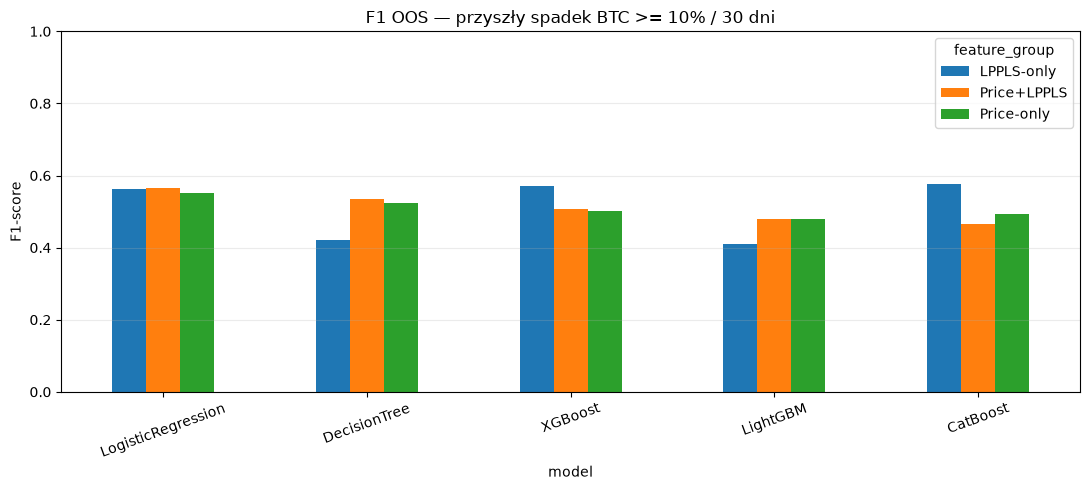

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,-0.029,0.015,0.007,10,30
1,DecisionTree,0.011,-0.013,-0.009,10,30
2,LightGBM,0.000,-0.019,-0.006,10,30
3,LogisticRegression,0.013,0.026,0.018,10,30
4,XGBoost,0.005,0.006,0.004,10,30


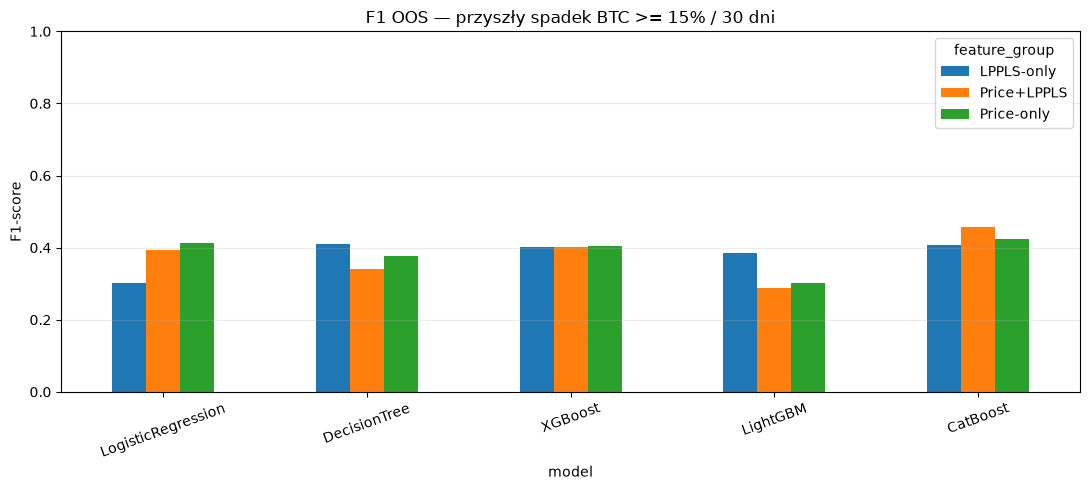

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,0.034,-0.016,-0.012,15,30
1,DecisionTree,-0.036,0.002,0.000,15,30
2,LightGBM,-0.013,-0.020,-0.015,15,30
3,LogisticRegression,-0.020,-0.004,-0.000,15,30
4,XGBoost,-0.002,-0.009,-0.006,15,30


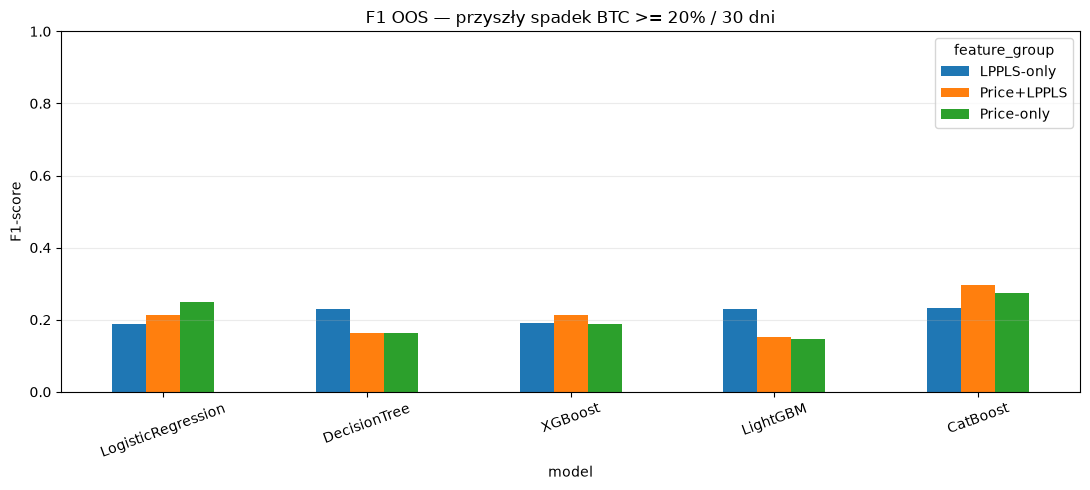

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,0.022,0.034,0.012,20,30
1,DecisionTree,0.000,0.006,-0.000,20,30
2,LightGBM,0.004,-0.009,-0.009,20,30
3,LogisticRegression,-0.036,-0.044,-0.005,20,30
4,XGBoost,0.025,0.004,-0.005,20,30


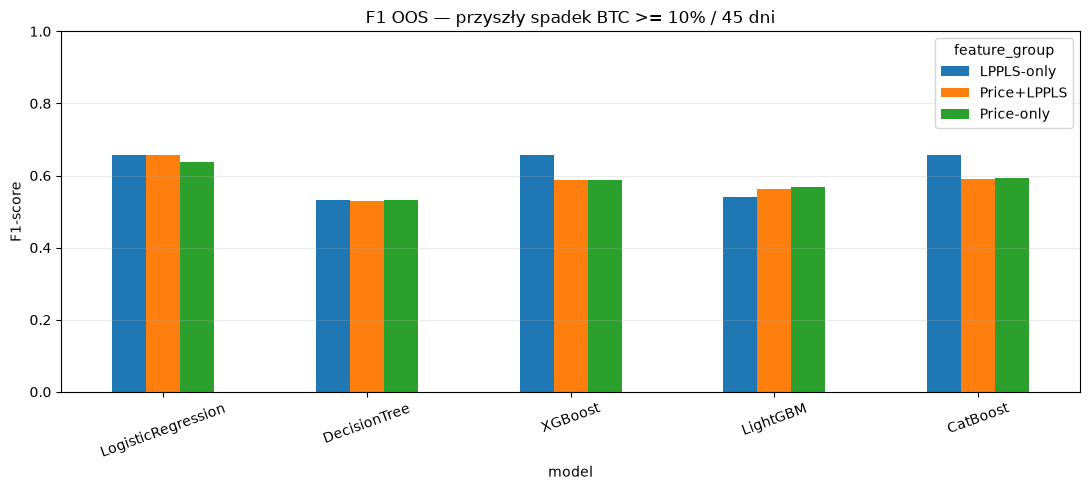

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,-0.004,0.021,0.005,10,45
1,DecisionTree,-0.002,0.000,0.000,10,45
2,LightGBM,-0.007,0.003,0.007,10,45
3,LogisticRegression,0.019,0.021,0.024,10,45
4,XGBoost,0.001,0.013,0.018,10,45


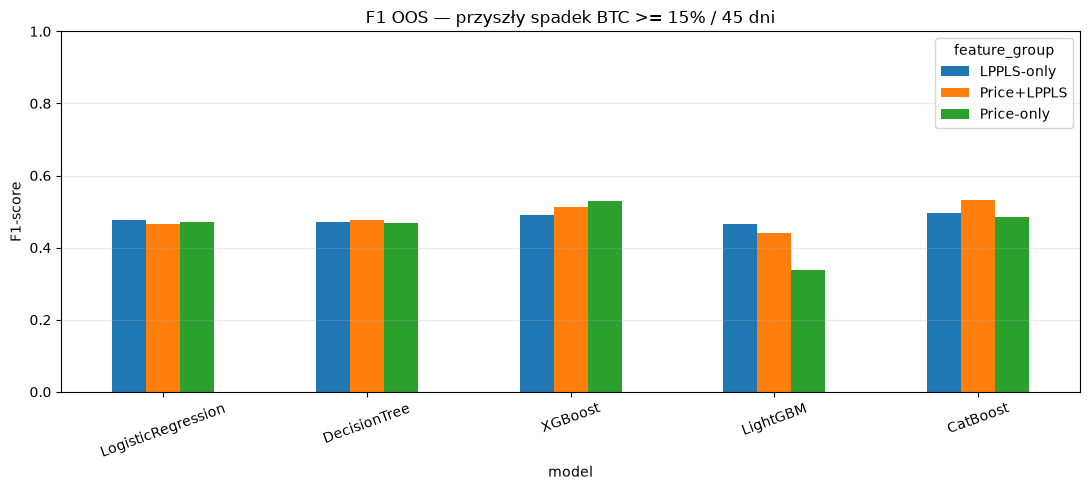

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,0.048,0.004,0.006,15,45
1,DecisionTree,0.009,0.006,0.002,15,45
2,LightGBM,0.101,0.026,0.009,15,45
3,LogisticRegression,-0.005,0.005,0.002,15,45
4,XGBoost,-0.016,0.002,0.001,15,45


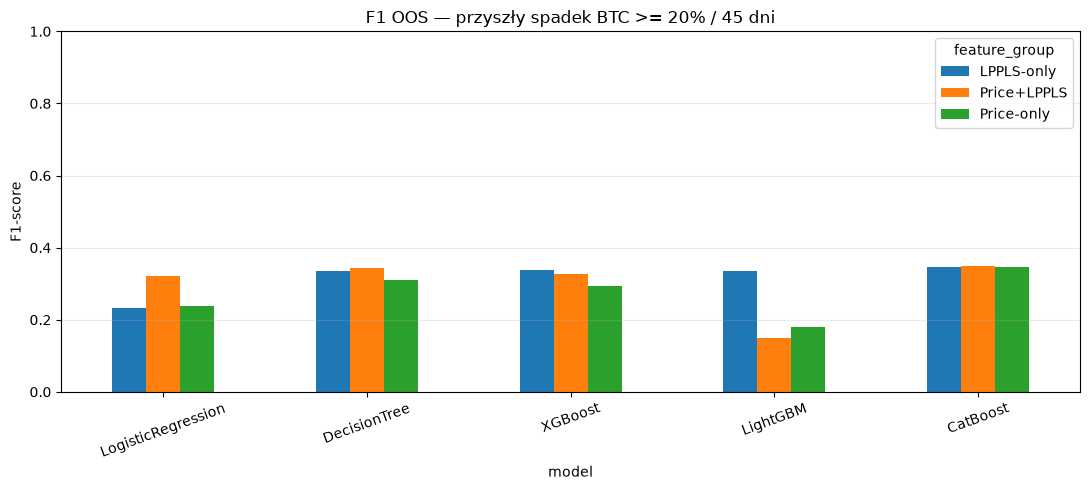

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,0.003,-0.017,-0.009,20,45
1,DecisionTree,0.034,0.014,0.008,20,45
2,LightGBM,-0.031,-0.010,-0.007,20,45
3,LogisticRegression,0.081,-0.032,-0.006,20,45
4,XGBoost,0.032,-0.002,0.001,20,45


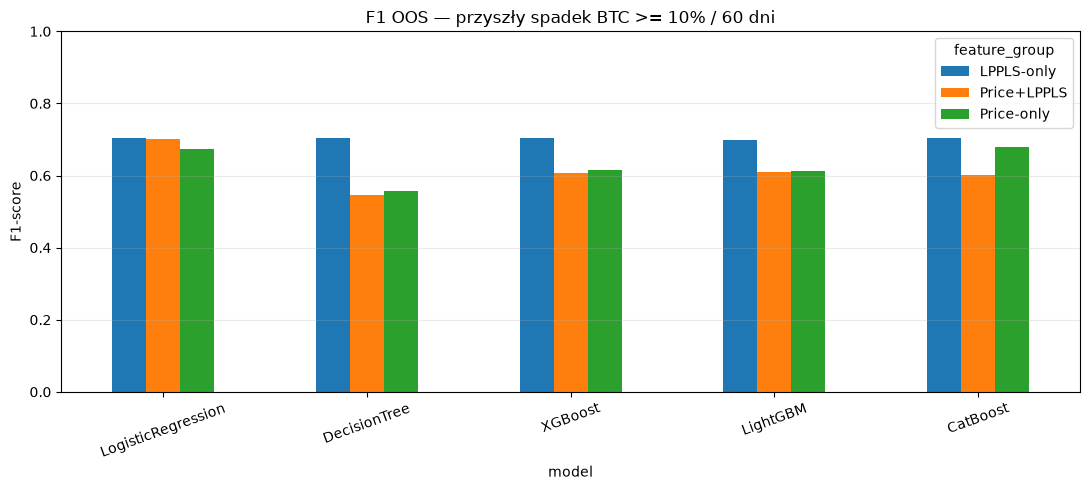

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,-0.076,0.013,0.010,10,60
1,DecisionTree,-0.011,0.017,0.011,10,60
2,LightGBM,-0.002,0.017,0.023,10,60
3,LogisticRegression,0.026,0.027,0.028,10,60
4,XGBoost,-0.008,0.014,0.018,10,60


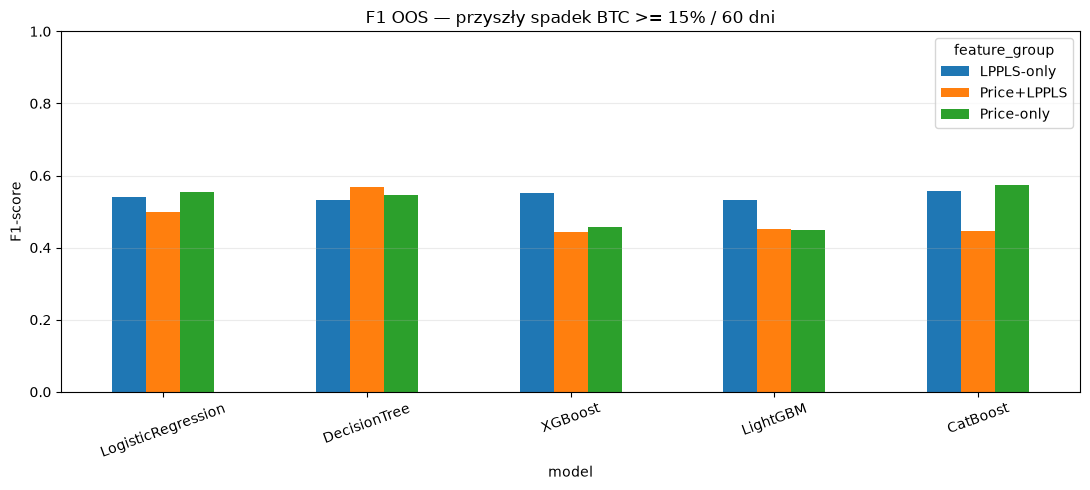

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,-0.128,-0.007,-0.006,15,60
1,DecisionTree,0.024,0.003,-0.000,15,60
2,LightGBM,0.004,-0.002,-0.004,15,60
3,LogisticRegression,-0.053,0.016,0.009,15,60
4,XGBoost,-0.014,0.002,0.004,15,60


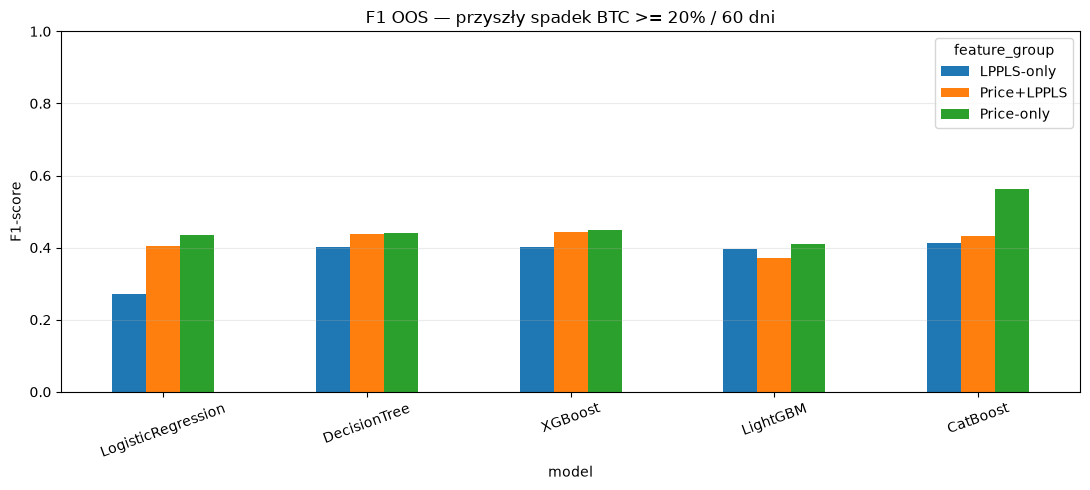

,model,delta_F1,delta_ROC_AUC,delta_AvgPrecision,drop_pct,horizon
0,CatBoost,-0.131,-0.017,-0.007,20,60
1,DecisionTree,-0.004,0.017,0.004,20,60
2,LightGBM,-0.037,-0.016,-0.011,20,60
3,LogisticRegression,-0.031,0.000,0.000,20,60
4,XGBoost,-0.006,-0.020,-0.012,20,60


Gotowe. Wyniki w katalogu: C:\Users\cynar\Desktop\projects\article\08_wyniki_modele


In [10]:
for drop,horizon in TARGET_CONFIGS:
    subset=summary.loc[(summary.drop_pct==drop)&(summary.horizon==horizon)].copy()
    ml=subset.loc[subset.feature_group!='Baseline']
    pivot=ml.pivot(index='model', columns='feature_group', values='f1')
    pivot=pivot.reindex(MODEL_NAMES)
    ax=pivot.plot.bar(figsize=(11,5),rot=20)
    ax.set_title(f'F1 OOS — przyszły spadek BTC >= {drop}% / {horizon} dni')
    ax.set_ylim(0,1);ax.set_ylabel('F1-score')
    ax.grid(axis='y',alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT/f'05_F1_modele_drop{drop}_h{horizon}.png',dpi=180)
    plt.show()

    price = ml.loc[ml.feature_group=='Price-only'].set_index('model')
    hybrid = ml.loc[ml.feature_group=='Price+LPPLS'].set_index('model')
    effect=pd.DataFrame({
        'delta_F1': hybrid['f1']-price['f1'],
        'delta_ROC_AUC': hybrid['roc_auc']-price['roc_auc'],
        'delta_AvgPrecision': hybrid['avg_precision']-price['avg_precision'],
    }).reset_index()
    effect['drop_pct']=drop;effect['horizon']=horizon
    display(effect.round(3))
    effect.to_csv(OUT/f'06_efekt_LPPLS_drop{drop}_h{horizon}.csv',index=False)

print('Gotowe. Wyniki w katalogu:', OUT.resolve())